# 15. Neo B với hàm sai số tuyệt đối

Sổ tay notebook 10 phát hiện một vấn đề phương pháp luận có hệ quả trực tiếp lên bảng kết quả của báo cáo. Độ lệch chuẩn ước lượng từ ba hạt giống thấp hơn ước lượng từ năm hạt giống khoảng một phẩy tám lần, một cách hệ thống ở cả hai cấu hình đo được. Ba điểm là quá ít để ước lượng độ phân tán, nên thanh sai số công bố từ ba hạt giống sẽ hẹp giả tạo. Đó là lí do thực hiện thử nghiệm bổ sung này.

Cấu hình neo B với hàm tuyệt đối hiện chỉ có ba hạt giống nhưng lại là cấu hình tốt nhất theo sai số tuyệt đối, tức là cấu hình sẽ được trích trong phần kết quả chính. Thanh sai số của nó vì vậy phải cùng chuẩn năm hạt giống với các cấu hình khác.

Thiết kế: dò lại ba hạt giống đã có trong notebook 09, huấn luyện bù hai hạt giống còn thiếu, rồi báo cáo trung bình, độ lệch chuẩn và biên độ trên cả năm. Sổ tay in song song ước lượng ba hạt giống và ước lượng năm hạt giống để lượng hóa đúng mức độ hẹp giả tạo. Chi phí ước lượng khoảng bốn phút.

> **Vị trí trong chuỗi tái lập:** notebook 15 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 04-Bon_phuong_an_neo, 09-Ba_ham_mat_mat_hai_neo, 11-Chi_so_theo_nhom_kenh.
>
> **Thư mục kết quả:** `Output/processed/w3_22_neo_b_ham_tuyet_doi_nam_hat_giong/`.
>
> **Mã định danh nội bộ:** `W3_22`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_22_neo_b_ham_tuyet_doi_nam_hat_giong"  #@param {type:"string"}
NGUON_BA_HAT_GIONG = "w3_16_ba_ham_mat_mat_hai_neo"  #@param {type:"string"}
NGUON_NEO_B_MSE = "bo_sung_04_neo_abcd"  #@param {type:"string"}
NGUON_NEO_B_MSE_DU_PHONG = "w3_18_chi_so_theo_nhom_kenh"  #@param {type:"string"}
N_BOOT = 5000  #@param {type:"integer"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

# Sổ tay này bắt buộc năm hạt giống, nên giá trị dưới đây ghi đè tham số chung.
N_SEEDS = 5
import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_22_neo_b_ham_tuyet_doi_nam_hat_giong
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:34:14
run_tag      w3_22_neo_b_ham_tuyet_doi_nam_hat_giong
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, dữ liệu và hàm dùng chung

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
# Sổ tay tuần 3 cần chính mô hình đã huấn luyện, không chỉ cần chỉ số tổng hợp,
# nên bản này giữ lại mô hình trong bộ nhớ và lưu trọng số ra đĩa.
MO_HINH_DA_HUAN_LUYEN = {}

def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    MO_HINH_DA_HUAN_LUYEN[ten] = model
    if ghi_file and kind != "persistence":
        torch.save(model.state_dict(), thu_muc / (ten + ".pt"))
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


In [8]:
# Đọc tổng sai số theo từng hồ sơ của nhiều tệp rồi lấy trung bình qua các hạt giống.
# Lấy trung bình trước khi bắt cặp, vì biến thiên do hạt giống không phải đối tượng cần đo.
def nap_tong_tu_danh_sach(danh_sach_tep):
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        d = np.load(t)
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


print("Đã định nghĩa hàm đọc tổng sai số theo hồ sơ")


Đã định nghĩa hàm đọc tổng sai số theo hồ sơ


In [9]:
# Mỗi ô của lưới được dò trong danh sách thư mục ứng viên của tuần 2. Quy ước đặt tên
# Giữa các đợt không hoàn toàn giống nhau nên phải thử nhiều tiền tố. Một ô chỉ được
# Nhận lại khi khớp đủ bốn điều kiện: cùng lần chạy nguồn, cùng độ dài cửa sổ, đúng neo
# Và đúng hàm mất mát. Ô nào không khớp thì bỏ và sẽ huấn luyện mới ở bước sau.
def tim_mot_o(ung_vien, neo_cho, mat_mat_cho, seed):
    for thu_muc_ten, tien_to in ung_vien:
        thu_muc = OUT_PROC / thu_muc_ten / "runs"
        tep_json = thu_muc / (tien_to + "_s" + str(seed) + ".json")
        tep_npz = thu_muc / (tien_to + "_s" + str(seed) + "_patient_sums.npz")
        if not (tep_json.exists() and tep_npz.exists()):
            continue
        d = json.loads(tep_json.read_text())
        hop_le = (d.get("read_tag") == READ_TAG and d.get("seq_len") == SEQ_LEN
                  and d.get("pred_len") == PRED_LEN and d.get("anchor") == neo_cho
                  and d.get("loai_mat_mat") == mat_mat_cho)
        if not hop_le:
            print("Bỏ qua", tien_to, "hạt giống", seed, "vì không khớp điều kiện ghép")
            continue
        return {"json": d, "npz": tep_npz, "nguon": thu_muc_ten, "tien_to": tien_to}
    return None


OUT_PROC = OUT / "processed"
print("Đã định nghĩa hàm dò kết quả cũ")


Đã định nghĩa hàm dò kết quả cũ


## 3. Dò lại phần đã chạy và huấn luyện phần còn thiếu

Phép dò theo từng hạt giống dùng lại nguyên hàm của notebook 09, nên điều kiện ghép vẫn là bốn điều kiện cũ: cùng lần chạy nguồn, cùng độ dài cửa sổ, đúng neo và đúng hàm mất mát. Hạt giống nào không khớp đủ bốn điều kiện sẽ bị huấn luyện lại thay vì nhận bừa.

In [10]:
SEEDS = list(range(N_SEEDS))
UNG_VIEN_MAE = [(NGUON_BA_HAT_GIONG, "nlinear_neoB_mae")]

KET_QUA = {}
THIEU = []
for s in SEEDS:
    tim = tim_mot_o(UNG_VIEN_MAE, "B", "mae", s)
    if tim is None:
        THIEU.append(s)
    else:
        KET_QUA[s] = tim
print("Đọc lại được", len(KET_QUA), "trên", len(SEEDS), "hạt giống")
print("Hạt giống cần huấn luyện mới:", THIEU)


Đọc lại được 3 trên 5 hạt giống
Hạt giống cần huấn luyện mới: [3, 4]


In [11]:
t0 = time.time()
p_per = chay_mot_cau_hinh("persistence", seed=0, nhan="persistence_luoi")
MAE_PERSISTENCE = float(p_per["test"]["mae"])
MSE_PERSISTENCE = float(p_per["test"]["mse"])

for s in THIEU:
    ten = "nlinear_neoB_mae_s" + str(s)
    d = chay_mot_cau_hinh("nlinear", anchor="B", seed=s, loai_mat_mat="mae", nhan=ten)
    KET_QUA[s] = {"json": d, "npz": RUNS / (ten + "_patient_sums.npz"),
                  "nguon": RUN_TAG, "tien_to": "nlinear_neoB_mae"}
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")


persistence_luoi                 MSE_obs 0.5788 | MAE_obs 0.4659 | 0 giây | 0 tham số
nlinear_neoB_mae_s3              MSE_obs 0.4402 | MAE_obs 0.4257 | 12 giây | 876 tham số
nlinear_neoB_mae_s4              MSE_obs 0.4398 | MAE_obs 0.4257 | 11 giây | 876 tham số
Tổng thời gian: 0.4 phút


## 4. Thống kê ba hạt giống so với năm hạt giống

Phép so sánh dưới đây không nhằm đổi giá trị trung bình, vì trung bình thường rất ổn định. Nó nhằm đo đúng một đại lượng: tỷ số giữa độ lệch chuẩn ước lượng từ năm điểm và độ lệch chuẩn ước lượng từ ba điểm đầu. Tỷ số lớn hơn một nghĩa là bảng kết quả dùng ba hạt giống đang báo thiếu độ phân tán.

In [12]:
mse = np.array([KET_QUA[s]["json"]["test"]["mse"] for s in SEEDS], dtype=np.float64)
mae = np.array([KET_QUA[s]["json"]["test"]["mae"] for s in SEEDS], dtype=np.float64)
for s, a, b in zip(SEEDS, mse, mae):
    print("Hạt giống", s, "| MSE", round(float(a), 6), "| MAE", round(float(b), 6),
          "| nguồn", KET_QUA[s]["nguon"])


def thong_ke(v):
    return {"so_hat_giong": int(len(v)), "trung_binh": float(np.mean(v)),
            "do_lech_chuan": float(np.std(v, ddof=1)) if len(v) > 1 else 0.0,
            "bien_do": float(np.max(v) - np.min(v))}


TK = {"mse_ba": thong_ke(mse[:3]), "mse_nam": thong_ke(mse),
      "mae_ba": thong_ke(mae[:3]), "mae_nam": thong_ke(mae)}
for khoa, v in TK.items():
    print(khoa.ljust(9), "trung bình", round(v["trung_binh"], 6),
          "| độ lệch chuẩn", round(v["do_lech_chuan"], 6),
          "| biên độ", round(v["bien_do"], 6))

ty_so_mse = TK["mse_nam"]["do_lech_chuan"] / max(TK["mse_ba"]["do_lech_chuan"], 1e-12)
ty_so_mae = TK["mae_nam"]["do_lech_chuan"] / max(TK["mae_ba"]["do_lech_chuan"], 1e-12)
print("Tỷ số độ lệch chuẩn năm trên ba, theo MSE:", round(ty_so_mse, 4))
print("Tỷ số độ lệch chuẩn năm trên ba, theo MAE:", round(ty_so_mae, 4))
KY_NANG_MAE = float(1.0 - TK["mae_nam"]["trung_binh"] / MAE_PERSISTENCE)
print("Chỉ số kỹ năng theo sai số tuyệt đối, năm hạt giống:", round(KY_NANG_MAE, 6))


Hạt giống 0 | MSE 0.439068 | MAE 0.425763 | nguồn w3_16_ba_ham_mat_mat_hai_neo
Hạt giống 1 | MSE 0.438065 | MAE 0.426077 | nguồn w3_16_ba_ham_mat_mat_hai_neo
Hạt giống 2 | MSE 0.438117 | MAE 0.425852 | nguồn w3_16_ba_ham_mat_mat_hai_neo
Hạt giống 3 | MSE 0.440217 | MAE 0.42574 | nguồn w3_22_neo_b_ham_tuyet_doi_nam_hat_giong
Hạt giống 4 | MSE 0.439829 | MAE 0.425679 | nguồn w3_22_neo_b_ham_tuyet_doi_nam_hat_giong
mse_ba    trung bình 0.438417 | độ lệch chuẩn 0.000564 | biên độ 0.001002
mse_nam   trung bình 0.439059 | độ lệch chuẩn 0.000976 | biên độ 0.002151
mae_ba    trung bình 0.425897 | độ lệch chuẩn 0.000162 | biên độ 0.000314
mae_nam   trung bình 0.425822 | độ lệch chuẩn 0.000156 | biên độ 0.000398
Tỷ số độ lệch chuẩn năm trên ba, theo MSE: 1.7287
Tỷ số độ lệch chuẩn năm trên ba, theo MAE: 0.9606
Chỉ số kỹ năng theo sai số tuyệt đối, năm hạt giống: 0.086108


## 5. Bắt cặp với neo B huấn luyện bằng hàm bình phương

Phép bắt cặp này lặp lại kiểm định của notebook 09 nhưng trên năm hạt giống thay vì ba. Mục đích là xác nhận lợi ích của hàm tuyệt đối không phụ thuộc vào số hạt giống. Phía đối chứng chỉ có ba hạt giống trong các lần chạy cũ, nên phần tổng sai số được lấy trên đúng số hạt giống có sẵn của từng phía và điều đó được ghi rõ trong tệp kết quả.

In [13]:
se_mae, ae_mae, dem_mae = nap_tong_tu_danh_sach([KET_QUA[s]["npz"] for s in SEEDS])

SEED_DOI_CHUNG = [0, 1, 2]
tep_mse = None
for thu_muc_ten, tien_to in [(NGUON_NEO_B_MSE, "nlinear_neoB"),
                             (NGUON_NEO_B_MSE_DU_PHONG, "nlinear_neoB_mse")]:
    ung = [OUT / "processed" / thu_muc_ten / "runs" /
           (tien_to + "_s" + str(s) + "_patient_sums.npz") for s in SEED_DOI_CHUNG]
    if all(t.exists() for t in ung):
        tep_mse = ung
        nguon_doi_chung = thu_muc_ten
        break

if tep_mse is None:
    print("Không thấy kết quả cũ, huấn luyện lại phía đối chứng")
    for s in SEED_DOI_CHUNG:
        chay_mot_cau_hinh("nlinear", anchor="B", seed=s, nhan="nlinear_neoB_mse_s" + str(s))
    tep_mse = [RUNS / ("nlinear_neoB_mse_s" + str(s) + "_patient_sums.npz")
               for s in SEED_DOI_CHUNG]
    nguon_doi_chung = RUN_TAG

se_mse, ae_mse, dem_mse = nap_tong_tu_danh_sach(tep_mse)
kq = hieu_so_bat_cap(se_mae, ae_mae, se_mse, ae_mse, dem_mae, n_boot=N_BOOT, seed=0)
print("Nguồn phía đối chứng:", nguon_doi_chung)
print("Hiệu MSE", round(kq["hieu_mse"], 6), kq["hieu_mse_ci"],
      "p", round(kq["p_hai_phia_mse"], 4))
print("Hiệu MAE", round(kq["hieu_mae"], 6), kq["hieu_mae_ci"],
      "p", round(kq["p_hai_phia_mae"], 4))
KIEM_DINH = {k: v for k, v in kq.items() if not k.startswith("mau_bootstrap")}


Nguồn phía đối chứng: bo_sung_04_neo_abcd
Hiệu MSE 0.003023 [-0.0005802086775456887, 0.006916680218337846] p 0.1072
Hiệu MAE -0.011454 [-0.012804912547555738, -0.0100825899240662] p 0.0


## 6. Hình phân tán theo hạt giống

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_22_neo_b_ham_tuyet_doi_nam_hat_giong/figures/W3_22_neo_b_mae_nam_hat_giong.png


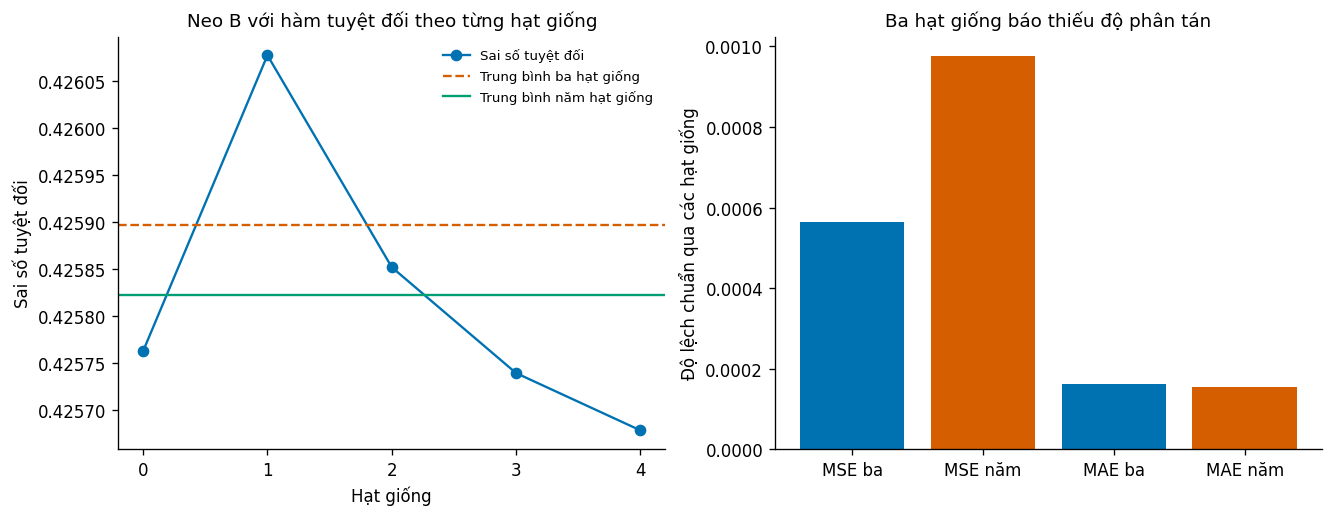

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.2))
ax[0].plot(SEEDS, mae, "o-", color=PALETTE[0], label="Sai số tuyệt đối")
ax[0].axhline(TK["mae_ba"]["trung_binh"], color=PALETTE[1], linestyle="--",
              label="Trung bình ba hạt giống")
ax[0].axhline(TK["mae_nam"]["trung_binh"], color=PALETTE[2], linestyle="-",
              label="Trung bình năm hạt giống")
ax[0].set_xticks(SEEDS)
ax[0].set_xlabel("Hạt giống")
ax[0].set_ylabel("Sai số tuyệt đối")
ax[0].set_title("Neo B với hàm tuyệt đối theo từng hạt giống")
ax[0].legend(fontsize=8)

nhan = ["MSE ba", "MSE năm", "MAE ba", "MAE năm"]
gia = [TK["mse_ba"]["do_lech_chuan"], TK["mse_nam"]["do_lech_chuan"],
       TK["mae_ba"]["do_lech_chuan"], TK["mae_nam"]["do_lech_chuan"]]
ax[1].bar(nhan, gia, color=[PALETTE[0], PALETTE[1], PALETTE[0], PALETTE[1]])
ax[1].set_ylabel("Độ lệch chuẩn qua các hạt giống")
ax[1].set_title("Ba hạt giống báo thiếu độ phân tán")
luu_hinh(fig, "W3_22_neo_b_mae_nam_hat_giong.png")
plt.show()


## 7. Ghi kết quả

In [15]:
ket_qua = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG, "read_tag": READ_TAG, "n_seeds": N_SEEDS,
    "n_boot": N_BOOT,
    "mse_persistence": MSE_PERSISTENCE, "mae_persistence": MAE_PERSISTENCE,
    "mse_theo_hat_giong": [float(v) for v in mse],
    "mae_theo_hat_giong": [float(v) for v in mae],
    "nguon_theo_hat_giong": {str(s): KET_QUA[s]["nguon"] for s in SEEDS},
    "thong_ke": TK,
    "ty_so_do_lech_chuan_mse": float(ty_so_mse),
    "ty_so_do_lech_chuan_mae": float(ty_so_mae),
    "ky_nang_mae_nam_hat_giong": KY_NANG_MAE,
    "so_hat_giong_doi_chung": len(SEED_DOI_CHUNG),
    "nguon_doi_chung": nguon_doi_chung,
    "kiem_dinh_mae_tru_mse": KIEM_DINH,
}
dich = RUN_DIR / "W3_neo_b_mae_nam_hat_giong.json"
dich.write_text(json.dumps(ket_qua, ensure_ascii=False, indent=2))
print("Đã ghi", dich)


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_22_neo_b_ham_tuyet_doi_nam_hat_giong/W3_neo_b_mae_nam_hat_giong.json
